# Session 13 — a 20M LLM, standard against reversible

The three 50M-token runs take hours, so they run from the command line (`./run_all.sh`, which calls `rev_train.py`).
This notebook (1) re-checks the reversible backward pass live, (2) re-measures memory, and (3) loads the logs of the
three full runs.

In [1]:
import json, sys, numpy as np, torch
sys.argv = ['x']
import rev_train as r
print('device', r.DEVICE, '| d', r.D, 'layers', r.LAYERS, 'heads', r.HEADS, 'context', r.CTX)
for v in ['standard', 'midpoint', 'revnet']:
    print(f'{v:9s} parameters {sum(p.numel() for p in r.LM(10000, v).parameters()):,}')

device mps | d 384 layers 9 heads 6 context 256


standard  parameters 19,870,848


midpoint  parameters 19,870,848


revnet    parameters 19,870,848


## 1. The reversible backward gives the same gradients as autograd (fp32)

In [2]:
train, val = r.load()
torch.manual_seed(0)
m = r.LM(10000, 'midpoint').to(r.DEVICE).float()
xb = r.batch(train, 4, np.random.default_rng(0))
F = torch.nn.functional
loss = F.cross_entropy(m(xb[:, :-1]).reshape(-1, 10000), xb[:, 1:].reshape(-1)); loss.backward()
g_rev = torch.cat([p.grad.flatten() for p in m.blocks.parameters()]); m.zero_grad()
x = m.emb(xb[:, :-1]) + m.pos(torch.arange(r.CTX, device=r.DEVICE)); prev, cur = x, x
for b in m.blocks: prev, cur = cur, prev + 2 * r.H * b(cur)            # same rule, ordinary autograd, everything stored
F.cross_entropy(m.head(m.norm(cur)).reshape(-1, 10000), xb[:, 1:].reshape(-1)).backward()
g_ref = torch.cat([p.grad.flatten() for p in m.blocks.parameters()])
print('relative gradient error, reversible vs autograd:', ((g_rev - g_ref).norm() / g_ref.norm()).item())
print('reconstruction error max |p[0] - p[-1]| (both should equal the input):', r.MidpointStack.recon)

relative gradient error, reversible vs autograd: 1.5567117088721716e-06
reconstruction error max |p[0] - p[-1]| (both should equal the input): 5.066394805908203e-07


## 2. Memory: the budget is the standard model at batch 32

In [3]:
probe = json.load(open('logs/memory_probe.json'))
print(f"budget {probe['budget_GiB']:.2f} GiB; largest batch inside it: {probe['max_batch']}")
for row in probe['rows']:
    if 'bs' in row: print(f"{row['variant']:9s} batch {row['bs']:4d}  peak {row['peak_GiB']:5.2f} GiB  {'fits' if row['fits'] else 'over'}")

budget 4.78 GiB; largest batch inside it: {'standard': 32, 'midpoint': 96}
standard  batch    8  peak  1.44 GiB  fits
standard  batch   16  peak  2.58 GiB  fits
standard  batch   32  peak  4.78 GiB  fits
standard  batch   48  peak  6.76 GiB  over
standard  batch   64  peak  9.18 GiB  over
midpoint  batch    8  peak  0.74 GiB  fits
midpoint  batch   16  peak  1.13 GiB  fits
midpoint  batch   32  peak  1.78 GiB  fits
midpoint  batch   48  peak  3.08 GiB  fits
midpoint  batch   64  peak  3.85 GiB  fits
midpoint  batch   96  peak  3.84 GiB  fits
midpoint  batch  128  peak  6.42 GiB  over
midpoint  batch  160  peak  6.42 GiB  over
midpoint  batch  192  peak  8.44 GiB  over


## 3. The three 50M-token runs

In [4]:
for n in ['standard', 'reversible', 'rev_maxbatch']:
    s = json.load(open(f'logs/{n}_summary.json'))
    print(f"{n:13s} {s['variant']:9s} batch {s['batch']:3d}  steps {s['steps']:5d}  tokens {s['tokens']:,}  "
          f"final train {s['final_train_loss']:.3f}  final val {s['final_val_loss']:.3f}  peak {s['peak_GiB']:.2f} GiB")
bench = json.load(open('logs/bench_idle.json'))
print('\nspeed measured on an idle machine (bench.py):')
for b in bench: print(f"{b['name']:13s} batch {b['batch']:3d}  {b['tok_s']:,} tok/s  {b['step_s']} s/step  peak {b['peak_GiB']} GiB")

standard      standard  batch  32  steps  6103  tokens 49,995,776  final train 2.636  final val 2.656  peak 4.53 GiB
reversible    midpoint  batch  32  steps  6103  tokens 49,995,776  final train 2.683  final val 2.716  peak 1.32 GiB
rev_maxbatch  midpoint  batch  96  steps  2034  tokens 49,987,584  final train 2.874  final val 2.905  peak 3.74 GiB

speed measured on an idle machine (bench.py):
standard      batch  32  12,425 tok/s  0.659 s/step  peak 4.51 GiB
reversible    batch  32  9,125 tok/s  0.898 s/step  peak 1.72 GiB
rev_maxbatch  batch  96  7,376 tok/s  3.332 s/step  peak 3.74 GiB


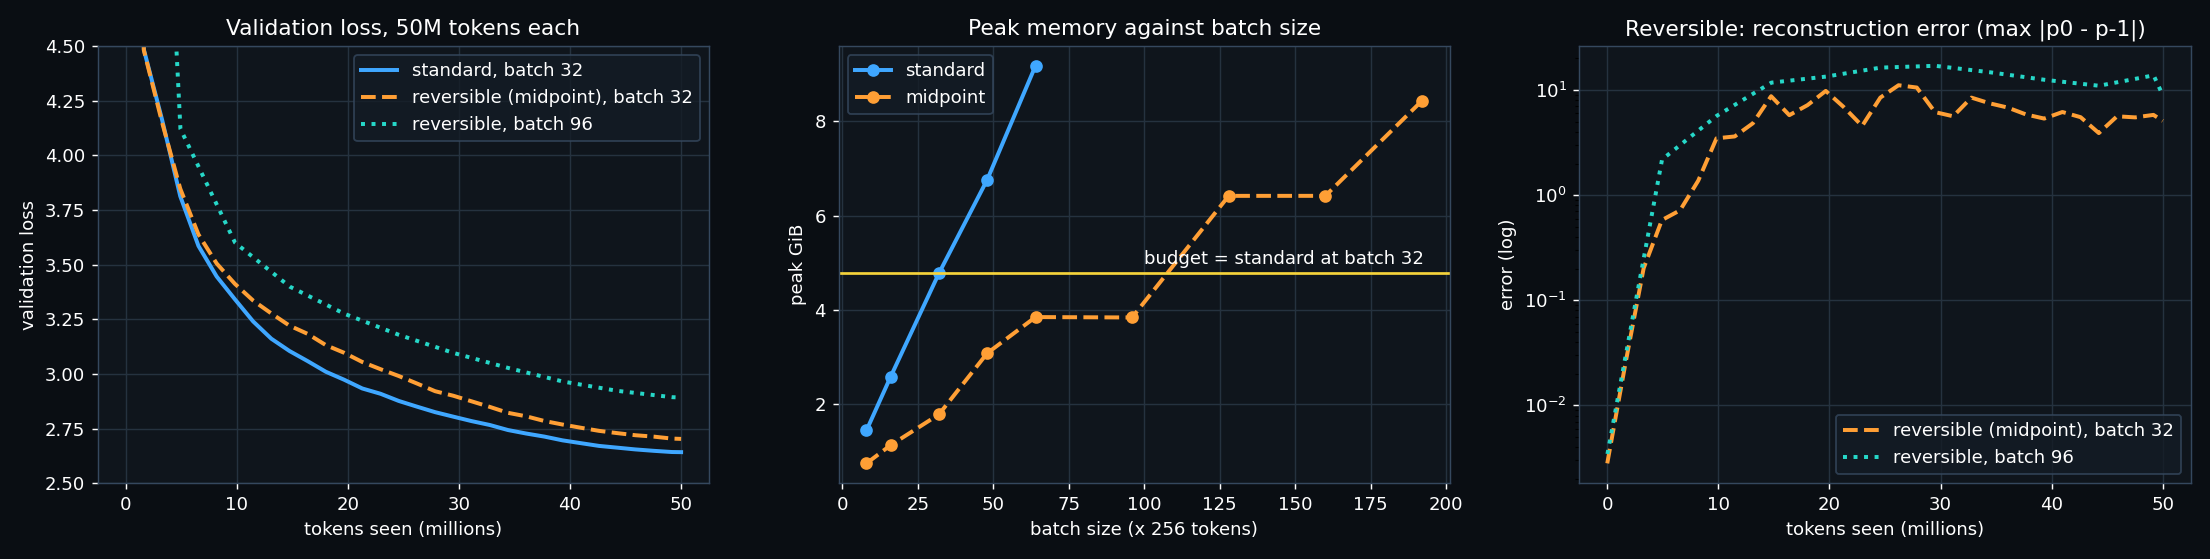

In [5]:
from IPython.display import Image
Image('figures/results.png')